In [1]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import glob
import os


In [2]:
data = pd.read_csv("données/LucasBenjamin_5bfc2227f88f3900014b0e1d.csv", skiprows=1, index_col=3)
data

,rt,url,trial_type,time_elapsed,internal_node_id,success,responses,view_history,trial_rt,response_rts,stimulus,presented_angles,stimulus_rotations,key_press,final_angle,confidence,target,score,correct
trial_index,,,,,,,,,,,,,,,,,,,
0,7626.0,external-consent.html,external-html,7845,0.0-0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,fullscreen,11311,0.0-1.0,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4173.0,NaN,survey-dropdown,15489,0.0-2.0,NaN,"{""0"":""25-40"",""1"":""F""}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2754.0,NaN,survey-text,18244,0.0-3.0,NaN,"{""Q0"":""5bfc2227f88f3900014b0e1d""}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,37344.0,NaN,instructions,55588,0.0-4.0,NaN,NaN,"[{""page_index"":0,""viewing_time"":6876},{""page_i...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,NaN,NaN,lb-SeqAns-visual,2569435,0.0-224.0,NaN,NaN,NaN,1063.0,NaN,Stims/Gabor_img/Gabor_0.png,"53.1515655535,-27.887777486,53.3709398815,97.3...","0,45,0,-45,-45",NaN,52.943472,0.0,52.025020,10.0,NaN
284,NaN,NaN,lb-SeqAns-visual,2582972,0.0-225.0,NaN,NaN,NaN,1413.0,NaN,Stims/Gabor_img/Gabor_0.png,"81.2042559657,47.3317891182,50.7685939314,27.9...","-45,-45,-45,0,0,45,-45",NaN,-4.923437,0.0,14.360958,4.0,NaN
285,NaN,NaN,lb-SeqAns-visual,2593665,0.0-226.0,NaN,NaN,NaN,1529.0,NaN,Stims/Gabor_img/Gabor_0.png,"93.238899764,50.355811416,55.5372974597,-1.443...","-45,0,0,45,45",NaN,-22.750976,0.0,59.685711,0.0,NaN


## Filtering du dataframe pour 1 sujet

In [3]:
df_filtered = data[data["stimulus_rotations"].notna()]
df_filtered = df_filtered.drop(columns=["rt", "url", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus"])
df_filtered.reset_index(drop=True, inplace=True)
df_filtered['presented_angles'] = df_filtered['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['score'] = df_filtered['score'].astype(int)
df_filtered["expected_angles"] = df_filtered.apply(lambda row : [x + y for x,y in zip(row["presented_angles"],row["stimulus_rotations"])], axis=1)
df_filtered["expected_targets"] = df_filtered['expected_angles'].apply(np.mean)%180 # the best they could have done with what they were given

df_filtered = df_filtered.dropna(subset=["final_angle"])

In [4]:
df_filtered

,trial_rt,presented_angles,stimulus_rotations,final_angle,target,score,expected_angles,expected_targets
0,2361.0,"[9.310117845, 4.7551440764, 7.2709294885, -49....","[0.0, 0.0, 0.0, 45.0, 45.0]",14.777374,9.313481,10,"[9.310117845, 4.7551440764, 7.2709294885, -4.7...",9.377164
1,2848.0,"[219.5799141215, 137.4455163865, 191.215447237...","[-45.0, 45.0, 0.0, 45.0, 0.0, -45.0, 45.0]",45.539492,177.673966,0,"[174.5799141215, 182.4455163865, 191.215447237...",177.557698
2,1190.0,"[94.6094147729, 49.8849493235, 68.845210001, 4...","[0.0, 0.0, 0.0, 45.0, 0.0]",42.580491,85.854540,0,"[94.6094147729, 49.8849493235, 68.845210001, 9...",85.951648
3,2361.0,"[127.3106455031, 165.0233036001, 168.314352999]","[45.0, 0.0, 0.0]",-22.818889,168.549276,8,"[172.3106455031, 165.0233036001, 168.314352999]",168.549434
4,3159.0,"[52.6728335367, 122.3995063762, 172.509632891,...","[45.0, 0.0, -45.0, -45.0, 0.0]",-13.648713,118.629940,0,"[97.6728335367, 122.3995063762, 127.509632891,...",118.633700
...,...,...,...,...,...,...,...,...
195,1063.0,"[53.1515655535, -27.887777486, 53.3709398815, ...","[0.0, 45.0, 0.0, -45.0, -45.0]",52.943472,52.025020,10,"[53.1515655535, 17.112222514, 53.3709398815, 5...",51.916819
196,1413.0,"[81.2042559657, 47.3317891182, 50.7685939314, ...","[-45.0, -45.0, -45.0, 0.0, 0.0, 45.0, -45.0]",-4.923437,14.360958,4,"[36.2042559657, 2.3317891181999997, 5.76859393...",14.360059
197,1529.0,"[93.238899764, 50.355811416, 55.5372974597, -1...","[-45.0, 0.0, 0.0, 45.0, 45.0]",-22.750976,59.685711,0,"[48.238899763999996, 50.355811416, 55.53729745...",60.533558
198,1836.0,[176.1292856348],[0.0],63.992103,176.129286,0,[176.1292856348],176.129286


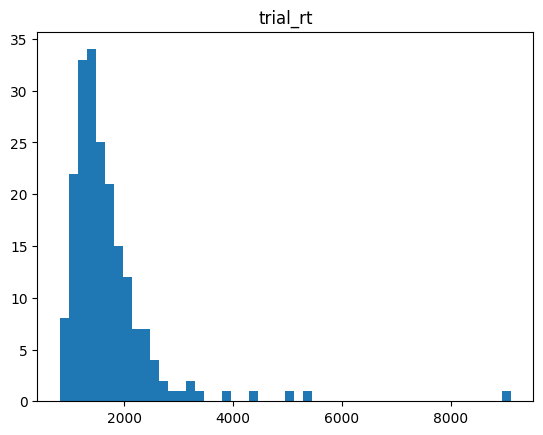

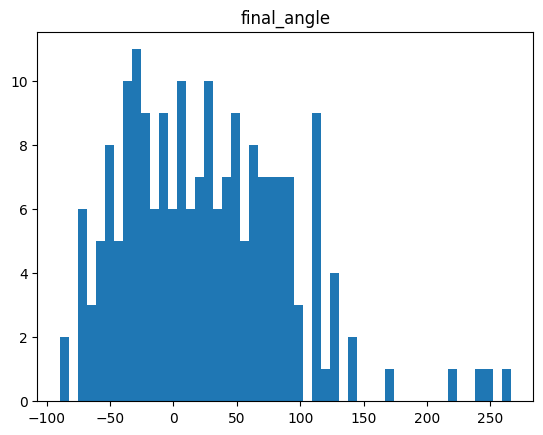

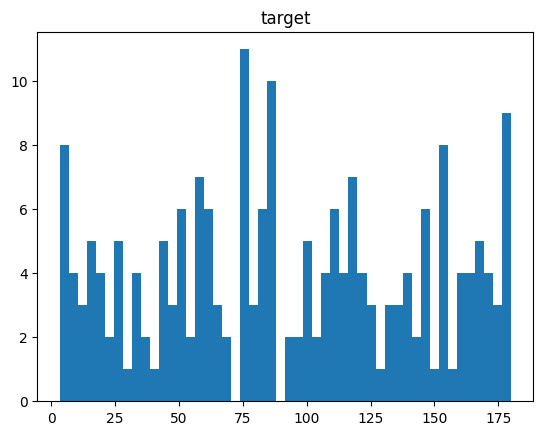

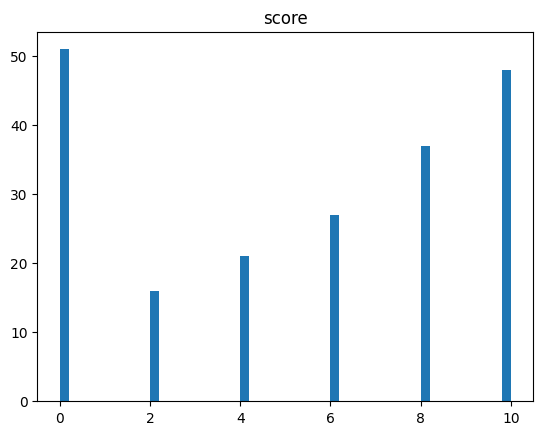

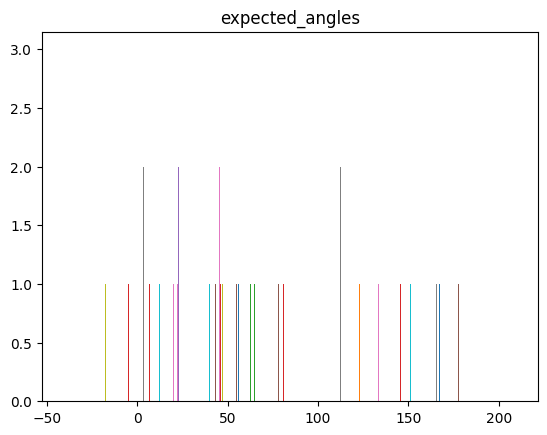

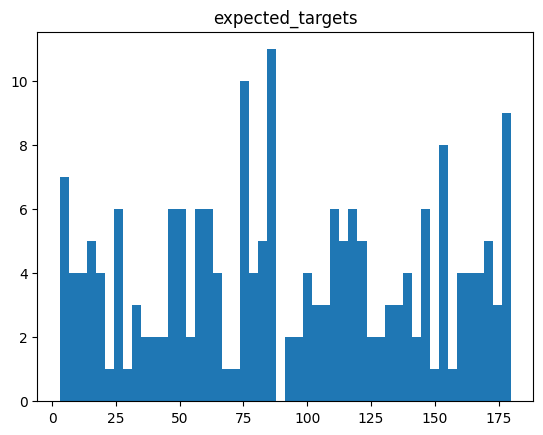

In [5]:
for column in df_filtered.columns:
    if column not in ["presented_angles", "stimulus_rotations"]:
        plt.figure()
        plt.hist(df_filtered[column], bins=50)
        plt.title(column)
        plt.show()

## Filtrage des données pour tous

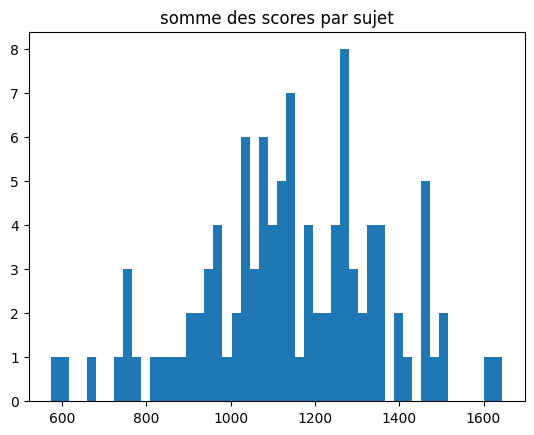

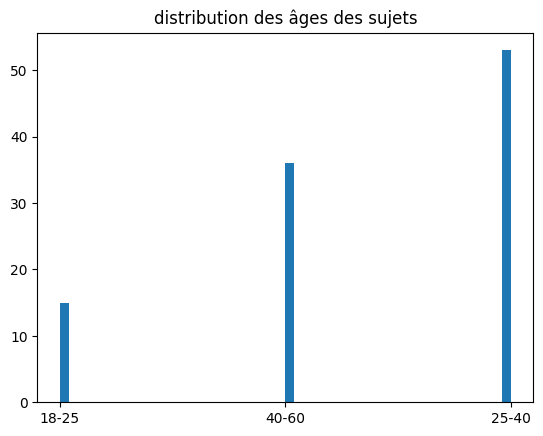

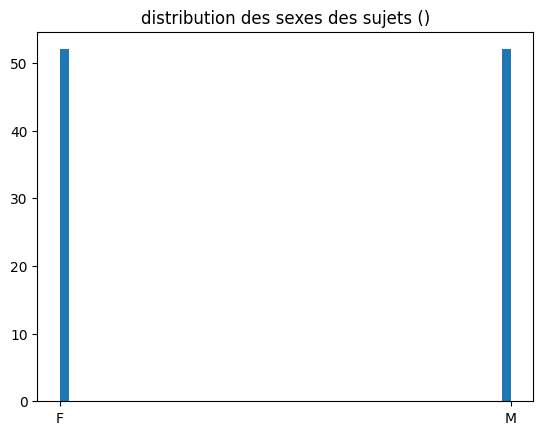

In [6]:
filepaths = glob.glob("données/*.csv")
dfs = [pd.read_csv(f, skiprows=1, index_col=3) for f in filepaths]

def data_sujets (dfs) : 
    score_sum = []
    age_tot = []
    sexe_tot = []
    for dfs in dfs :     
        age = dfs['responses'][dfs["trial_type"]== 'survey-dropdown'][2][6:11]
        sexe = dfs['responses'][dfs["trial_type"]== 'survey-dropdown'][2][18]
        age_tot = age_tot + [age]
        sexe_tot = sexe_tot + [sexe]
        
        df_filtered = dfs[dfs["stimulus_rotations"].notna()]
        df_filtered = df_filtered.drop(columns=["rt", "url", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus"])
        df_filtered.reset_index(drop=True, inplace=True)
        df_filtered['presented_angles'] = df_filtered['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
        df_filtered['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
        df_filtered['score'] = df_filtered['score'].astype(int)
        df_filtered = df_filtered.dropna(subset=["final_angle"])
        score_sum.append(df_filtered["score"].sum())
        
    return score_sum, age, age_tot, sexe, sexe_tot


plt.hist(data_sujets(dfs)[0], bins=50)
plt.title("somme des scores par sujet")
plt.show()

plt.hist(data_sujets(dfs)[2], bins=50)
plt.title("distribution des âges des sujets")
plt.show()

plt.hist(data_sujets(dfs)[4], bins=50)
plt.title(f"distribution des sexes des sujets ()")
plt.show()

In [7]:
print("il y a",data_sujets(dfs)[4].count('F'), "femmes"), print("il y a",data_sujets(dfs)[4].count('M'), 'hommes'), print("il y a",data_sujets(dfs)[2].count('18-25'), "personnes qui ont entre 18 et 25 ans"),
print("il y a",data_sujets(dfs)[2].count('25-40'), 'personnes qui ont entre 25 et 40 ans'), print("il y a",data_sujets(dfs)[2].count('40-60'), 'personnes qui ont entre 40 et 60 ans')

il y a 52 femmes
il y a 52 hommes
il y a 15 personnes qui ont entre 18 et 25 ans
il y a 53 personnes qui ont entre 25 et 40 ans
il y a 36 personnes qui ont entre 40 et 60 ans


(None, None)

## Dispositoin des angles sur un cercle

je met tous les angles que ce participant a tiré, pour voir si il tire plutôt sur la parcelle de 0° à 180°, ou si il va au-delà.

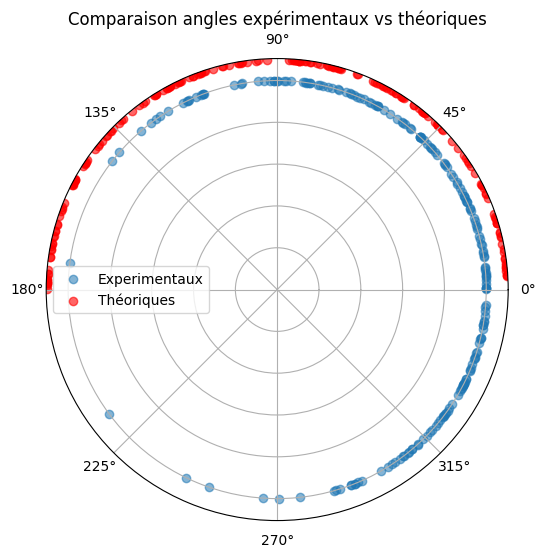

In [8]:
fig = plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)

# angles en radians
theta_presented = np.deg2rad(df_filtered['final_angle'].values)
theta_targets = np.deg2rad(df_filtered['target'].values
)


# rayon arbitraire (juste pour séparer les couches)
ax.scatter(theta_presented, np.ones_like(theta_presented),
           alpha=0.55, label="Experimentaux")

ax.scatter(theta_targets, np.ones_like(theta_targets)*1.1,
           color='red', alpha=0.6, label="Théoriques")

ax.set_yticklabels([])
ax.set_title("Comparaison angles expérimentaux vs théoriques")

ax.legend()
plt.show()



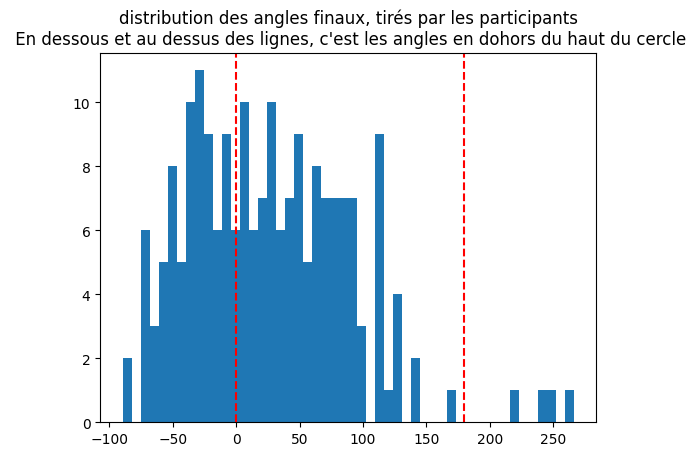

In [9]:
plt.hist(df_filtered["final_angle"], bins=50)
plt.axvline(0, color='red', linestyle='--')
plt.axvline(180, color='red', linestyle='--')
plt.title("distribution des angles finaux, tirés par les participants\n En dessous et au dessus des lignes, c'est les angles en dohors du haut du cercle")
plt.show()

## implication des rotations dans la détermination des angles

fonction d'erreur circulaire 

In [10]:
def distance_circular_error(a, b):
    return ((a - b + 90) % 180) - 90

In [11]:
def angle_modulo_180(angle):
    return angle % 180

In [12]:
for angle in df_filtered["expected_angles"][0]:
    old = angle
    new = angle_modulo_180(angle)
    print("old =", old, "new =", new)

old = 9.310117845 new = 9.310117845
old = 4.7551440764 new = 4.7551440764
old = 7.2709294885 new = 7.2709294885
old = -4.704121881500001 new = 175.2958781185
old = 30.253748608000002 new = 30.253748608000002


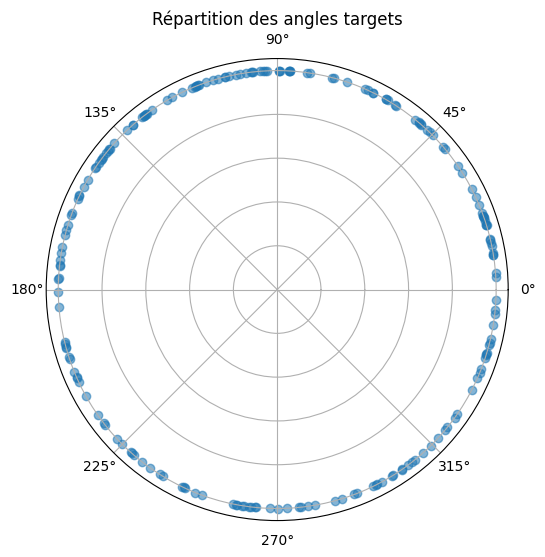

In [13]:
fig = plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)

ax.scatter(df_filtered['expected_targets'], np.ones_like(df_filtered['expected_targets']),
           alpha=0.55)

ax.set_yticklabels([])
ax.set_title("Répartition des angles targets")
plt.show()

est ce que les participants ont bien répondu ? : performances 

In [14]:
df_filtered["error_to_target"] = distance_circular_error(df_filtered["final_angle"], df_filtered["expected_targets"])

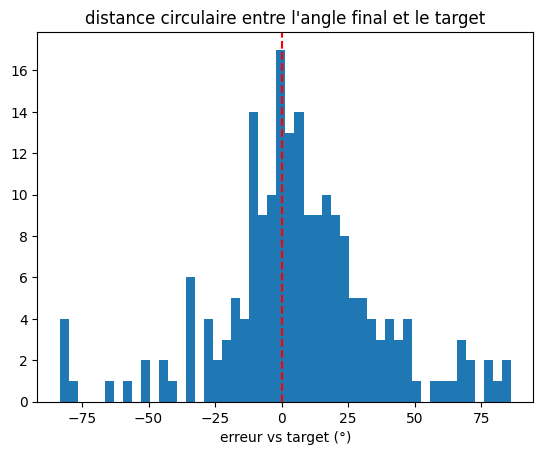

In [15]:
plt.hist(df_filtered["error_to_target"], bins=50)
plt.axvline(0, color='red', linestyle='--') 
plt.xlabel("erreur vs target (°)")
plt.title("distance circulaire entre l'angle final et le target")
plt.show()

est ce que ce participant se comporte en ignorant la rotation ?

In [31]:
# 1. regarder la moyenne circulaire des angles vues par les participants
mean_presented_angles = df_filtered['presented_angles'].apply(np.mean)

In [34]:
df_filtered['rotation_error'] = distance_circular_error(
    (df_filtered['final_angle'])%180,
    mean_presented_angles%180
)

In [35]:
df_filtered['rotation_error']

0      23.400210
1      54.410366
2     -34.371157
3       3.631677
4      38.717587
         ...    
195    -7.973347
196   -38.569211
197   -74.284534
198    67.862817
199   -63.900891
Name: rotation_error, Length: 200, dtype: float64

Erreur = ce que le participant a répondu
− ce qu’il aurait dû répondre s’il appliquait parfaitement la rotation

Gros pic autour de 0°
➡️ Les gens font bien la rotation

Pics autour de ±45°
➡️ Les gens répondent comme s’il n’y avait pas de rotation

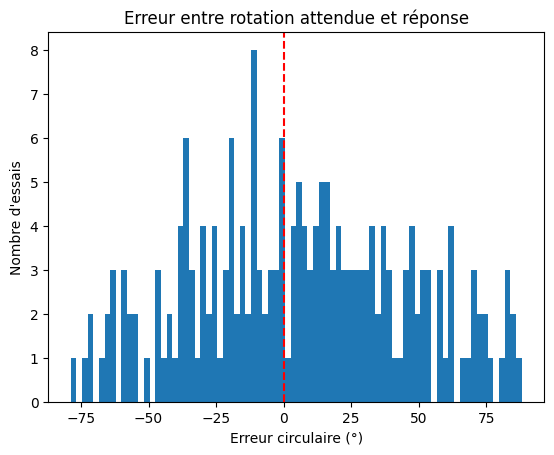

In [36]:
plt.hist(df_filtered['rotation_error'], bins=80)
plt.axvline(0, color='red', linestyle='--')
plt.xlabel("Erreur circulaire (°)")
plt.ylabel("Nombre d'essais")
plt.title("Erreur entre rotation attendue et réponse")
plt.show()


In [ ]:
df_filtered['rotation_type'] = rotation_sum.map({
    -45: '-45',
     0: '0',
     45: '+45'
})


Est-ce que certaines rotations sont plus difficiles que d’autres ?

boîte centrée sur 0 → rotation bien faite

boîte décalée → biais systématique

boîte large → imprécision


0° : bien centré → OK

+45° : décalé vers −20° → sous-rotation

−45° : très dispersé → confus@

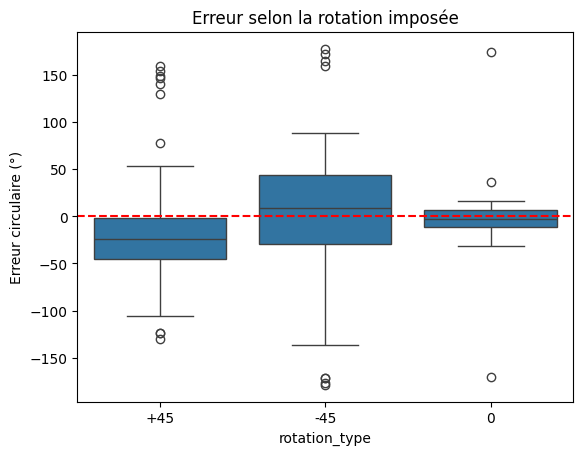

In [ ]:
import seaborn as sns

sns.boxplot(
    x='rotation_type',
    y='rotation_error',
    data=df_filtered
)
plt.axhline(0, color='red', linestyle='--')
plt.ylabel("Erreur circulaire (°)")
plt.title("Erreur selon la rotation imposée")
plt.show()


Est-ce que rater la rotation fait baisser le score ?

Si + l’erreur augmente, plus le score chute, alors le score reflète la capacité à intégrer la rotation

Si il n'y a pas de relation, alors le score dépend d’autre chose (bruit perceptif, attention…)


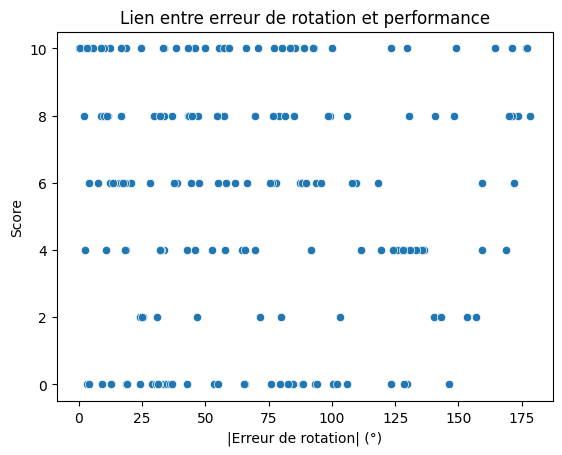

In [ ]:
sns.scatterplot(
    x=np.abs(df_filtered['rotation_error']),
    y=df_filtered['score']
)
plt.xlabel("|Erreur de rotation| (°)")
plt.ylabel("Score")
plt.title("Lien entre erreur de rotation et performance")
plt.show()


➡️ Pas de relation
➡️ Le score dépend d’autre chose (bruit perceptif, attention…)

In [ ]:
df_filtered[['rotation_error', 'score']].corr()


,rotation_error,score
rotation_error,1.000000,-0.028993
score,-0.028993,1.000000


In [ ]:
df_filtered['final_rel_target'] = circular_error(
    df_filtered['final_angle'],
    df_filtered['target']
)


Les gens répondent-ils toujours autour de la target
ou bien la rotation déforme systématiquement leur réponse ?

toutes les boîtes centrées sur 0
→ target bien représentée, rotation intégrée

boîtes décalées selon la rotation
→ la rotation crée un biais cognitif


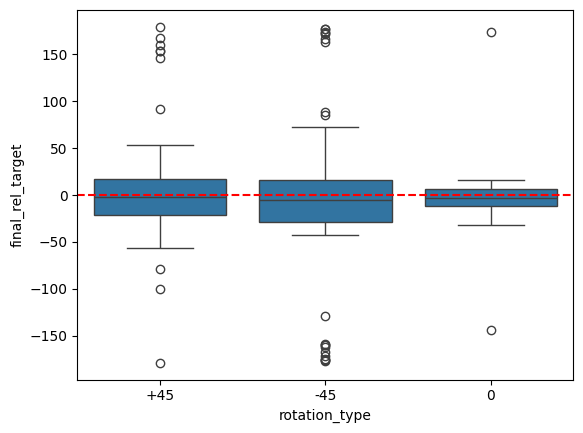

In [ ]:
sns.boxplot(
    x='rotation_type',
    y='final_rel_target',
    data=df_filtered
)
plt.axhline(0, color='red', linestyle='--')
plt.show()


toutes les boîtes centrées sur 0
→ target bien représentée, rotation intégrée

boîtes décalées selon la rotation
→ la rotation crée un biais cognitif